# Agents, Session 8, Part 2: MCP with CrewAI, and an Introduction to A2A

In Part 1 you built MCP servers and connected them to Claude Desktop. Now two final steps:

1. **MCP with CrewAI:** give the CrewAI agents from Sessions 6 and 7 tools from an MCP server, in one line.
2. **An introduction to A2A:** the protocol for agents talking to *other agents*, and how it fits with MCP.

### Why a second notebook?

CrewAI and FastMCP 4 (Part 1) need different versions of the same library (`mcp`), so they can't be installed together. This notebook uses CrewAI's environment:

- **Colab:** open this notebook in a fresh session.
- **VS Code:** choose the environment you used for Sessions 6 and 7, which already has CrewAI. Don't install CrewAI into your Part 1 environment.

This part needs your **Gemini key** again, for the CrewAI agent.

In [ ]:
%pip install -q "crewai[google-genai]>=1.15" requests python-dotenv

In [ ]:
import os
import sys
os.environ["CREWAI_TRACING_ENABLED"] = "false"

from getpass import getpass
from crewai import Agent, Task, Crew, LLM
from crewai.mcp import MCPServerStdio

try:
    from google.colab import userdata                        # only exists on Colab
    os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
except Exception:
    from dotenv import load_dotenv
    load_dotenv(".env")                                       # VS Code: read the .env file next to this notebook
if not os.getenv("GOOGLE_API_KEY"):
    os.environ["GOOGLE_API_KEY"] = getpass("Paste your Gemini API key: ")

llm = LLM(model="gemini/gemini-3.5-flash-lite", api_key=os.environ["GOOGLE_API_KEY"])
print("Ready:", llm.model)

## 1. MCP with CrewAI

In Sessions 6 and 7 we gave CrewAI agents tools by writing Python functions with `@tool`. Those tools only worked inside that one script.

With MCP, the tools live in an **MCP server**, and any MCP client can use them: Claude Desktop, an IDE, **or a CrewAI agent**. CrewAI has an MCP client built in. You add one setting to an agent:

```python
Agent(..., mcps=[my_server])
```

CrewAI then starts the server, asks it which tools it has, and gives those tools to the agent.

### Step 1: an MCP server with a useful tool

Our server offers two tools: a calculator, and a real 7-day weather forecast (from Open-Meteo, free, no key).

*A small difference from Part 1: here we import FastMCP from the official `mcp` library (`from mcp.server.fastmcp import FastMCP`). That's the original FastMCP, built into the library CrewAI uses. The decorators are the same as in Part 1.*

In [ ]:
%%writefile travel_server.py
import requests
from mcp.server.fastmcp import FastMCP

mcp = FastMCP("Travel Tools")

@mcp.tool()
def add_numbers(a: float, b: float) -> float:
    """Add two numbers together.

    Args:
        a: First number
        b: Second number
    """
    return a + b

@mcp.tool()
def get_weather_forecast(place: str) -> str:
    """Get the weather forecast for the next 7 days for a town, for example Manali.

    Args:
        place: The town or city.
    """
    try:
        found = requests.get("https://geocoding-api.open-meteo.com/v1/search",
                             params={"name": place, "count": 1}, timeout=20).json()
        if "results" not in found:
            return f"Could not find a place called {place}."
        town = found["results"][0]
        daily = requests.get("https://api.open-meteo.com/v1/forecast", timeout=20, params={
            "latitude": town["latitude"], "longitude": town["longitude"], "timezone": "auto",
            "daily": "temperature_2m_min,temperature_2m_max"}).json()["daily"]
    except Exception as error:
        return f"The weather service is unavailable right now ({type(error).__name__})."
    lines = []
    for day in range(len(daily["time"])):
        lines.append(f"{daily['time'][day]}: {daily['temperature_2m_min'][day]} to {daily['temperature_2m_max'][day]} C")
    return f"7-day forecast for {town['name']}: " + "; ".join(lines)

if __name__ == "__main__":
    mcp.run(transport="stdio")

### Step 2: tell CrewAI how to start the server

`MCPServerStdio` holds the same two things as the Claude Desktop configuration in Part 1: the **Python program** to run, and the **server file**.

One detail: CrewAI names each tool after its server, so tools from different servers can never clash. A tool name is limited to 64 characters, so we keep the paths **short** (relative to this notebook's folder). That way the agent sees readable names like `..._get_weather_forecast` instead of a long path cut off in the middle.

In [ ]:
try:
    python_command = os.path.relpath(sys.executable)   # a short path keeps tool names readable
except ValueError:
    python_command = sys.executable                    # Windows, when Python is on another drive

travel_server = MCPServerStdio(command=python_command, args=["travel_server.py"])
print("CrewAI will run:", python_command, "travel_server.py")

Before running a crew, let's look at the tools CrewAI finds on the server. `get_mcp_tools` connects, sends a `tools/list` request, and turns each MCP tool into a CrewAI tool. No Gemini calls yet.

In [ ]:
inspector = Agent(role="Inspector", goal="List tools.", backstory="You inspect servers.", llm=llm)

for mcp_tool in inspector.get_mcp_tools([travel_server]):
    print(f"{mcp_tool.name}\n    {mcp_tool.description.splitlines()[0]}")

Each tool keeps the name and description from the server's docstrings. The start of each name identifies the server.

*If your names look cut off (this happens when your Python is far from this notebook's folder), don't worry: the tools still work, because the agent chooses a tool by reading its description.*

### Step 3: an agent that uses the MCP tools

The only new line is `mcps=[travel_server]`. We write no `@tool` functions in this notebook: the agent's tools come entirely from the MCP server.

With `verbose=True`, watch for the **Tool Output** box between "Agent Started" and "Agent Final Answer": that's the answer that came back from the MCP server.

In [ ]:
travel_assistant = Agent(
    role="Travel assistant",
    goal="Help couples plan trips using real weather data.",
    backstory="You always check the forecast with your tools before advising.",
    llm=llm,
    mcps=[travel_server],                 # all of this agent's tools come from the MCP server
    max_rpm=4,
    verbose=True,
)

weather_task = Task(
    description="A couple is visiting Manali this week. Check the forecast, then say in three sentences "
                "what to pack, mentioning the coldest and warmest temperatures.",
    expected_output="Three sentences of packing advice based on the forecast.",
    agent=travel_assistant,
)

crew = Crew(agents=[travel_assistant], tasks=[weather_task], max_rpm=4)
result = await crew.kickoff_async()
print("\nADVICE:\n" + result.raw)

Here's what just happened, step by step:

1. CrewAI **started** `travel_server.py` as a separate program (stdio, like Claude Desktop does).
2. It completed the MCP **handshake** and asked for the **list of tools**.
3. The agent read the tool descriptions and decided to call `get_weather_forecast`: a **`tools/call`** request.
4. The server fetched the real forecast and sent the result back through MCP.

The *same* `travel_server.py` works unchanged in Claude Desktop: add it to the configuration from Part 1. **Write the tool once; use it from any MCP client.** That's the whole point of the protocol.

### Step 4 (VS Code): use your Part 1 server from CrewAI

The protocol is the contract: CrewAI doesn't care how a server was built, or which Python runs it. In VS Code, you can point CrewAI at Part 1's FastMCP 4 server, run by **Part 1's Python** (the environment where FastMCP 4 is installed):

```python
part1_server = MCPServerStdio(
    command="../session8/.venv/bin/python",                 # Part 1's Python (Windows: ..\\session8\\.venv\\Scripts\\python.exe)
    args=["../session8/servers/mcpserver_tools.py"],        # Part 1's server file
)
math_agent = Agent(role="Mathematician", goal="Calculate accurately.", backstory="You use tools for arithmetic.",
                   llm=llm, mcps=[part1_server])
```

Two different environments with two different library versions, talking happily through MCP. Adjust the two paths to where your Part 1 folder is.

### Step 5: remote MCP servers

Servers can also run on the internet, over **Streamable HTTP**. For those, CrewAI uses `MCPServerHTTP`:

```python
from crewai.mcp import MCPServerHTTP

remote_server = MCPServerHTTP(url="https://example.com/mcp", headers={"Authorization": "Bearer YOUR_TOKEN"})
agent = Agent(..., mcps=[remote_server])
```

**Only connect agents to servers you trust.** An MCP tool runs whatever code the server's author wrote, and a tool's description is text the model reads, so a malicious server could try to steer your agent. Keep tokens in environment variables, never in code.

## 2. An introduction to A2A: agents talking to agents

MCP connects an agent to its **tools**. But what if your agent needs help from **another agent**, one built by a different team, with a different framework, running on someone else's servers?

Say DilSeTrips' trip planner (built with CrewAI) wants an airline's booking agent (built with something else) to book a flight. The planner can't import the airline's code, and the airline won't share its internal tools. They need a common language for agents. That's **A2A (Agent2Agent)**.

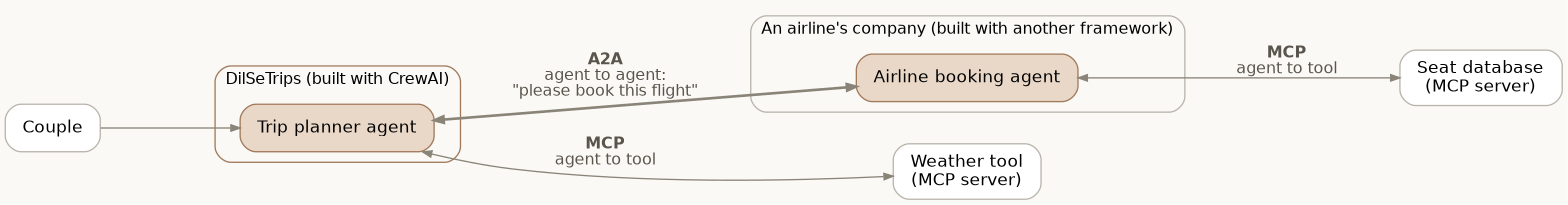

*MCP connects each agent to its own tools. A2A connects agents to each other, even across companies and frameworks.*

### Where A2A comes from

Google introduced A2A in April 2025 and donated it to the Linux Foundation that June. Version 1.0, the first stable release, came out in March 2026, and in August 2026 A2A joined the **Agentic AI Foundation**, the same Linux Foundation group that looks after MCP. Over 150 organisations support it, and frameworks including CrewAI, LangGraph and Google's ADK can use it.

### The four big ideas

**1. Agent Card: "here's who I am and what I can do".** Every A2A agent publishes a small JSON document at a standard web address, `/.well-known/agent-card.json`, describing its name, its **skills**, where to reach it, and how to authenticate. Other agents read the card to discover what it can do, a bit like MCP's `tools/list`, but for a whole agent. *(Older tutorials use `agent.json`; the name changed in 2025.)*

Here's a simplified Agent Card for a DilSeTrips flight agent:

In [ ]:
import json

agent_card = {
    "name": "DilSeTrips Flight Agent",
    "description": "Finds and compares flights within India for couples.",
    "version": "1.0.0",
    "supportedInterfaces": [{"url": "https://agents.dilsetrips.example/a2a", "protocolBinding": "JSONRPC"}],
    "capabilities": {"streaming": True, "pushNotifications": False},
    "defaultInputModes": ["text/plain"],
    "defaultOutputModes": ["text/plain", "application/json"],
    "skills": [{
        "id": "search_flights",
        "name": "Search flights",
        "description": "Finds direct or one-stop flights between Indian cities, with prices in rupees.",
        "examples": ["Find a direct flight from Mumbai to Goa on 20 December"],
    }],
}
print(json.dumps(agent_card, indent=2))

*A simplified example for learning; the specification lists every field, such as authentication schemes and signatures.*

**2. Task: a piece of work with a status.** When one agent asks another for help, the request becomes a **task** that moves through states. Some tasks finish in seconds; others take hours, so the asking agent can check back, or get updates as they happen.

| State | Meaning |
|---|---|
| `submitted` | Received, not started yet |
| `working` | In progress |
| `input-required` | Paused: the agent needs more information (like elicitation in MCP) |
| `auth-required` | Paused: the agent needs the user to sign in or authorise something |
| `completed` | Finished successfully |
| `failed` | Something went wrong |
| `canceled` | Stopped on request |
| `rejected` | The agent declined the task |

**3. Messages and parts: the conversation.** Agents exchange **messages** (from the `user` side or the `agent` side). Each message is made of **parts**: text, a file, or structured JSON data. So agents can send more than plain text.

**4. Artifacts: the results.** The finished outputs of a task, such as a booking confirmation, a report, or an image, come back as **artifacts**.

### How A2A messages travel

A2A uses familiar web technology: **JSON-RPC 2.0 over HTTP**, the same message format MCP uses. Results can come back in three ways: wait for the answer; **stream** updates as they happen; or have the remote agent call you back later (**push notifications**) for long tasks. Version 1.0 also offers gRPC and plain HTTP/REST.

One important principle: **agents stay opaque**. The airline's agent never reveals its prompts, memory or tools; it only shows its Agent Card and returns results. Companies can collaborate without exposing their internals.

### MCP and A2A, side by side

| | MCP | A2A |
|---|---|---|
| Connects | An agent to its **tools and data** | An agent to **other agents** |
| Direction | Vertical: an agent reaching down to its tools | Horizontal: agents working as peers |
| You discover... | A server's tools, resources and prompts | An agent's skills, from its Agent Card |
| A request is... | One tool call, usually quick | A task that may take a long time, with states |
| Each side sees... | The tool's inputs and outputs | Only results: each agent stays opaque |
| Example | Your planner calls a weather tool | Your planner asks an airline's agent to book |

They're **partners, not rivals**. The A2A project's own one-line summary: **MCP inside agents, A2A between agents.** In Session 7's terms, MCP and A2A are standard rules for **communication**, so that **coordination** and **cooperation** can work across tools, teams and even companies.

## 3. Session 8 conclusions

1. **Protocols are shared rules** for exchanging messages: consistent, reliable, interoperable and secure.
2. **MCP standardises how AI applications connect to tools and data.** A **host** contains the LLM; each **client** talks to one **server**; servers offer **tools** (the model decides), **resources** (the app decides) and **prompts** (the user picks).
3. **FastMCP makes servers easy:** decorate ordinary functions. Run them locally over **stdio** or remotely over **Streamable HTTP**.
4. **Write once, use anywhere:** the same server works in **Claude Desktop** and as tools for a **CrewAI** agent (`mcps=[...]`), even across different environments.
5. **A2A lets agents work with other agents,** across teams, frameworks and companies, through Agent Cards, tasks, messages and artifacts. **MCP inside agents, A2A between agents.**

## Exercises

1. **[Easy]** Add a `convert_inr_to_usd(amount)` tool to `travel_server.py` (use a fixed rate, and say so in the docstring). Ask the travel assistant for a budget in both currencies.
2. **[Easy]** Run the tool-listing cell again after adding your tool. Did CrewAI pick it up without any other change?
3. **[Medium]** Give the travel assistant **two** servers: `mcps=[travel_server, another_server]`, where `another_server` runs a second file with a `get_packing_list(season)` tool. How are tools from two servers kept apart?
4. **[Medium]** Add `travel_server.py` to Claude Desktop's configuration (Part 1, section 8) and ask Claude for Manali's forecast. Same server, two different clients.
5. **[Discussion]** Write an Agent Card (as a Python dictionary) for a DilSeTrips **destination agent** with two skills. What should it reveal to other agents, and what should stay private?

## Quick reference

| Idea | Code |
|---|---|
| A server in CrewAI's environment | `from mcp.server.fastmcp import FastMCP` (same decorators as Part 1) |
| A local server for CrewAI | `MCPServerStdio(command=python_path, args=["server.py"])` |
| A remote server for CrewAI | `MCPServerHTTP(url="https://...", headers={...})` |
| Give an agent MCP tools | `Agent(..., mcps=[server])` |
| See which tools CrewAI found | `agent.get_mcp_tools([server])` |
| A2A discovery | the Agent Card at `/.well-known/agent-card.json` |
| A2A task states | submitted, working, input-required, auth-required, completed, failed, canceled, rejected |